# Tuned In: Formative User Feedback, Round 3 analysis

This notebook reads one uploaded Iteration 3 ZIP file containing all participant export ZIPs. It provides descriptive analysis of task performance, adaptive decisions, and music transitions.

Run the cells from top to bottom after setting the Iteration 3 ZIP path below.


## Questions covered

- How many participants, completed blocks, records, decisions, and transitions are available?
- How did speed, error rate, and correction effort differ by participant?
- Did the adaptive engine have enough records to evaluate its rules?
- Which playback states and decision reasons occurred?
- Did music crossfades complete near their configured duration?

This is formative analysis. It supports refinement and retesting, not causal conclusions about music.


In [1]:
from io import BytesIO
from pathlib import Path
import json
import zipfile

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")


In [2]:
# Change this only if you move or rename the uploaded Iteration 3 ZIP file.
ITERATION_ZIP = Path(
    "/Users/zi/Documents/GitHub/TunedIn-Web/feedback-files/results/iterative-3.zip"
)
assert ITERATION_ZIP.is_file(), f"File not found: {ITERATION_ZIP}"


In [3]:
TABLE_NAMES = ("blocks", "records", "decisions", "transitions", "tracks")

def matches(name, filename):
    return name == filename or name.endswith("/" + filename)

def load_export_zip(zip_bytes, source_zip):
    # Supports files at the ZIP root or inside a nested results folder.
    tables = {name: [] for name in TABLE_NAMES}
    sessions = []

    with zipfile.ZipFile(BytesIO(zip_bytes)) as archive:
        names = [
            name for name in archive.namelist()
            if "__MACOSX" not in name and not name.endswith("/")
        ]

        for table_name in TABLE_NAMES:
            filename = table_name + ".csv"
            for name in names:
                if matches(name, filename):
                    table = pd.read_csv(BytesIO(archive.read(name)))
                    table["source_zip"] = source_zip
                    tables[table_name].append(table)

        for name in names:
            if matches(name, "session.json"):
                session = json.loads(archive.read(name))
                session["source_zip"] = source_zip
                sessions.append(session)

    return tables, sessions

loaded_tables = {name: [] for name in TABLE_NAMES}
loaded_sessions = []

with zipfile.ZipFile(ITERATION_ZIP) as iteration_archive:
    participant_zips = [
        name for name in iteration_archive.namelist()
        if name.lower().endswith(".zip") and "__MACOSX" not in name
    ]

    assert participant_zips, "The uploaded ZIP does not contain participant export ZIP files."
    print("Participant export ZIPs found:", len(participant_zips))

    for member_name in sorted(participant_zips):
        print("-", member_name)
        participant_tables, participant_sessions = load_export_zip(
            iteration_archive.read(member_name),
            Path(member_name).name,
        )
        for name in TABLE_NAMES:
            loaded_tables[name].extend(participant_tables[name])
        loaded_sessions.extend(participant_sessions)

def combine(name):
    return (
        pd.concat(loaded_tables[name], ignore_index=True)
        if loaded_tables[name] else pd.DataFrame()
    )

blocks = combine("blocks")
records = combine("records")
decisions = combine("decisions")
transitions = combine("transitions")
tracks = combine("tracks")
sessions = pd.DataFrame(loaded_sessions)


Participant export ZIPs found: 3
- FUF_Round3_P002_exports_20261017.zip
- FUF_Round3_P003_exports_20261016.zip
- tuned-in-75d3d179-bf94-4395-b425-acca671b998c-results.zip


In [4]:
print(f"Participants: {sessions['participantId'].nunique()}")
print(f"Block rows: {len(blocks)}")
print(f"Record rows: {len(records)}")
print(f"Adaptive decisions: {len(decisions)}")
print(f"Music transitions: {len(transitions)}")

session_columns = [
    column for column in [
        "participantId", "studyMode", "buildVersion",
        "randomizationSeed", "comfortVolumePercent", "timing", "source_zip",
    ] if column in sessions.columns
]
sessions[session_columns]


Participants: 3
Block rows: 8
Record rows: 101
Adaptive decisions: 27
Music transitions: 9


,participantId,studyMode,buildVersion,randomizationSeed,comfortVolumePercent,timing,source_zip
0,F3-P002,Formative,fuf-iteration-3.0.1,fuf3.0.1,50,"{'practiceSeconds': 60, 'baselineSeconds': 120...",FUF_Round3_P002_exports_20261017.zip
1,F3-P003,Formative,fuf-iteration-3.0.1,fuf3.0.1,20,"{'practiceSeconds': 60, 'baselineSeconds': 120...",FUF_Round3_P003_exports_20261016.zip
2,P001,Formative,fuf-iteration-3.0.1-timing-1m-2m-5m,fuf3.0.1,38,"{'practiceSeconds': 60, 'baselineSeconds': 120...",tuned-in-75d3d179-bf94-4395-b425-acca671b998c-...


## Block performance

Validated records per minute describes completed records per minute. First-pass error rate is the share of records rejected on the first submission. Median IL is initiation latency, while median FPED is first-pass entry duration.


In [5]:
if "attempt_status" in blocks.columns:
    completed_blocks = blocks.loc[blocks["attempt_status"].eq("completed")].copy()
else:
    completed_blocks = blocks.copy()

numeric_block_columns = [
    "block", "duration_seconds", "records_presented", "validated_records",
    "validated_records_per_minute", "median_il_ms", "median_fped_ms",
    "first_pass_error_rate", "first_pass_accuracy", "median_ttsv_ms",
    "correction_cycles", "correction_cycles_per_validated_record",
]
for column in numeric_block_columns:
    if column in completed_blocks.columns:
        completed_blocks[column] = pd.to_numeric(
            completed_blocks[column], errors="coerce"
        )

block_columns = [
    "participant_id", "block", "condition", "duration_seconds",
    "records_presented", "validated_records", "validated_records_per_minute",
    "median_il_ms", "median_fped_ms", "first_pass_error_rate",
    "correction_cycles",
]
completed_blocks[
    [column for column in block_columns if column in completed_blocks.columns]
].sort_values(["participant_id", "block"])


,participant_id,block,condition,duration_seconds,records_presented,validated_records,validated_records_per_minute,median_il_ms,median_fped_ms,first_pass_error_rate,correction_cycles
0,F3-P002,0,No music,60,3,2,2.000,"3,266.850","14,659.700",0.500,2
1,F3-P002,1,No music,120,8,7,3.500,"1,965.300","13,468.200",0.143,1
2,F3-P002,2,Adaptive music,300,21,20,4.000,"1,514.000","12,835.900",0.050,1
3,F3-P003,1,No music,120,7,6,3.000,"2,156.000","13,796.250",0.500,3
4,F3-P003,2,Adaptive music,300,18,17,3.400,"1,559.900","14,114.400",0.235,5
5,P001,0,No music,60,6,5,5.000,"1,205.000","9,971.000",0.000,0
6,P001,1,No music,120,12,11,5.500,"1,189.000","8,952.000",0.000,0
7,P001,2,Adaptive music,300,26,25,5.000,"1,069.000","8,888.000",0.080,3


In [6]:
adaptive_blocks = completed_blocks.loc[
    completed_blocks["condition"].eq("Adaptive music")
].copy()

adaptive_columns = [
    "participant_id", "duration_seconds", "validated_records",
    "validated_records_per_minute", "median_il_ms", "median_fped_ms",
    "first_pass_error_rate", "correction_cycles",
]
adaptive_blocks[
    [column for column in adaptive_columns if column in adaptive_blocks.columns]
].sort_values("participant_id")


,participant_id,duration_seconds,validated_records,validated_records_per_minute,median_il_ms,median_fped_ms,first_pass_error_rate,correction_cycles
2,F3-P002,300,20,4.000,"1,514.000","12,835.900",0.050,1
4,F3-P003,300,17,3.400,"1,559.900","14,114.400",0.235,5
7,P001,300,25,5.000,"1,069.000","8,888.000",0.080,3


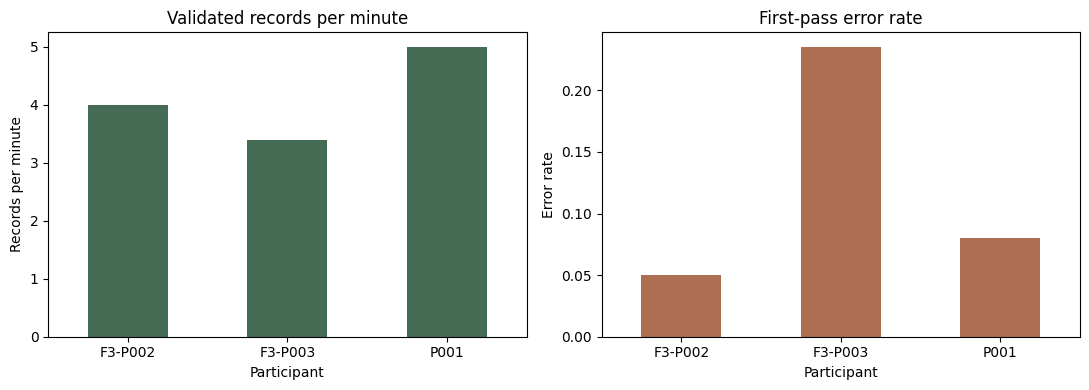

In [7]:
if not adaptive_blocks.empty:
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))

    adaptive_blocks.plot.bar(
        x="participant_id", y="validated_records_per_minute",
        ax=axes[0], legend=False, color="#456b55",
        title="Validated records per minute",
    )
    axes[0].set(xlabel="Participant", ylabel="Records per minute")
    axes[0].tick_params(axis="x", rotation=0)

    adaptive_blocks.plot.bar(
        x="participant_id", y="first_pass_error_rate",
        ax=axes[1], legend=False, color="#ad6e51",
        title="First-pass error rate",
    )
    axes[1].set(xlabel="Participant", ylabel="Error rate")
    axes[1].tick_params(axis="x", rotation=0)

    plt.tight_layout()


## Adaptive-rule eligibility and state selection

An evaluation is eligible when its rolling window contains at least the required number of records. Ineligible evaluations retain the prior playback state. Change the settings below only for offline exploration.


In [8]:
# Current Round 3 settings.
MINIMUM_RECORD_COUNT = 3
ELEVATED_IL_MULTIPLIER = 0.95
ELEVATED_FPED_MULTIPLIER = 0.95
ELEVATED_ERROR_RATE = 0.10

decision_numbers = [
    "block", "record_count", "median_il_ms", "median_fped_ms",
    "first_pass_error_rate", "baseline_il_ms", "baseline_fped_ms",
]
for column in decision_numbers:
    if column in decisions.columns:
        decisions[column] = pd.to_numeric(decisions[column], errors="coerce")

decisions["eligible"] = decisions["record_count"] >= MINIMUM_RECORD_COUNT
decisions["il_ratio"] = decisions["median_il_ms"] / decisions["baseline_il_ms"]
decisions["fped_ratio"] = (
    decisions["median_fped_ms"] / decisions["baseline_fped_ms"]
)

eligibility = (
    decisions.groupby("participant_id", as_index=False)
    .agg(
        evaluations=("eligible", "size"),
        eligible_evaluations=("eligible", "sum"),
        mean_records_in_window=("record_count", "mean"),
    )
)
eligibility["eligible_percent"] = (
    100 * eligibility["eligible_evaluations"] / eligibility["evaluations"]
)
eligibility


,participant_id,evaluations,eligible_evaluations,mean_records_in_window,eligible_percent
0,F3-P002,9,9,4.000,100.000
1,F3-P003,9,8,3.333,88.889
2,P001,9,9,5.111,100.000


In [9]:
state_counts = (
    decisions.pivot_table(
        index="participant_id", columns="selected_state",
        values="block", aggfunc="size", fill_value=0,
    )
    .reindex(columns=["baseline", "reduced", "elevated"], fill_value=0)
    .reset_index()
)

reason_counts = (
    decisions.groupby(["participant_id", "reason"], as_index=False)
    .size()
    .sort_values(["participant_id", "size"], ascending=[True, False])
)

state_counts


selected_state,participant_id,baseline,reduced,elevated
0,F3-P002,5,2,2
1,F3-P003,1,6,2
2,P001,5,4,0


In [10]:
reason_counts

,participant_id,reason,size
0,F3-P002,Neither reduced nor elevated trigger condition...,5
1,F3-P002,Recent performance met a reduced-state trigger.,2
2,F3-P002,Recent performance met every elevated-state tr...,2
5,F3-P003,Recent performance met a reduced-state trigger.,5
6,F3-P003,Recent performance met every elevated-state tr...,2
3,F3-P003,Kept the previous state while waiting for enou...,1
4,F3-P003,Neither reduced nor elevated trigger condition...,1
7,P001,Neither reduced nor elevated trigger condition...,5
8,P001,Recent performance met a reduced-state trigger.,4


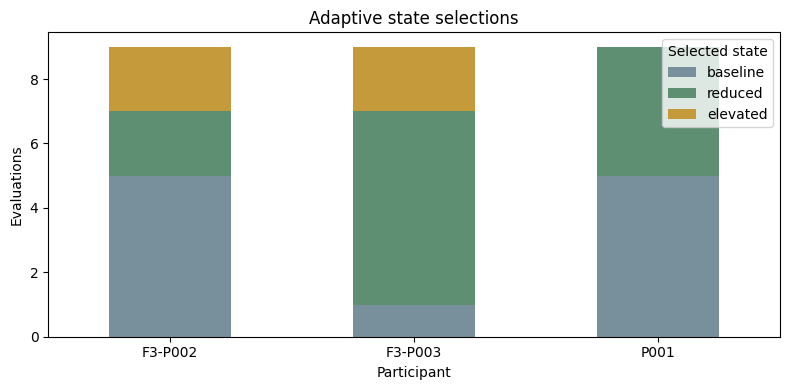

In [11]:
if not decisions.empty:
    plot_data = (
        decisions.groupby(["participant_id", "selected_state"])
        .size()
        .unstack(fill_value=0)
        .reindex(columns=["baseline", "reduced", "elevated"], fill_value=0)
    )
    plot_data.plot(
        kind="bar", stacked=True, figsize=(8, 4),
        color={"baseline": "#78909c", "reduced": "#5f8f72", "elevated": "#c49a3a"},
        title="Adaptive state selections",
    )
    plt.xlabel("Participant")
    plt.ylabel("Evaluations")
    plt.xticks(rotation=0)
    plt.legend(title="Selected state")
    plt.tight_layout()


## Offline Elevated-rule exploration

This changes neither the application nor the exports. It only tests alternative Elevated conditions against the recorded decisions.


In [12]:
def simulate_elevated(minimum_records, il_multiplier, fped_multiplier, max_error_rate):
    eligible = decisions.loc[
        decisions["record_count"] >= minimum_records
    ].copy()
    eligible["would_select_elevated"] = (
        (eligible["il_ratio"] <= il_multiplier)
        & (eligible["fped_ratio"] <= fped_multiplier)
        & (eligible["first_pass_error_rate"] <= max_error_rate)
    )
    return eligible

candidates = pd.DataFrame([
    {
        "minimum_records": MINIMUM_RECORD_COUNT,
        "il_multiplier": ELEVATED_IL_MULTIPLIER,
        "fped_multiplier": ELEVATED_FPED_MULTIPLIER,
        "max_error_rate": ELEVATED_ERROR_RATE,
    },
    {"minimum_records": 3, "il_multiplier": 0.98, "fped_multiplier": 0.98, "max_error_rate": 0.10},
    {"minimum_records": 3, "il_multiplier": 1.00, "fped_multiplier": 1.00, "max_error_rate": 0.10},
])

def candidate_summary(row):
    result = simulate_elevated(**row.to_dict())
    selected = result.loc[result["would_select_elevated"]]
    return pd.Series({
        "eligible_evaluations": len(result),
        "would_select_elevated": int(result["would_select_elevated"].sum()),
        "elevated_percent_of_eligible": (
            100 * result["would_select_elevated"].mean() if len(result) else 0
        ),
        "participants_reaching_elevated": (
            ", ".join(sorted(selected["participant_id"].unique()))
            if not selected.empty else "None"
        ),
    })

pd.concat([candidates, candidates.apply(candidate_summary, axis=1)], axis=1)


,minimum_records,il_multiplier,fped_multiplier,max_error_rate,eligible_evaluations,would_select_elevated,elevated_percent_of_eligible,participants_reaching_elevated
0,3,0.950,0.950,0.100,26,4,15.385,"F3-P002, F3-P003"
1,3,0.980,0.980,0.100,26,9,34.615,"F3-P002, F3-P003, P001"
2,3,1.000,1.000,0.100,26,11,42.308,"F3-P002, F3-P003, P001"


## Music-transition checks

Actual crossfade duration is completed time minus started time. A successful duration near the configured crossfade duration indicates that the browser completed the requested transition.


In [13]:
transition_numbers = [
    "block", "started_ms", "completed_ms", "configured_crossfade_ms",
]
for column in transition_numbers:
    if column in transitions.columns:
        transitions[column] = pd.to_numeric(transitions[column], errors="coerce")

if not transitions.empty:
    transitions["actual_crossfade_ms"] = (
        transitions["completed_ms"] - transitions["started_ms"]
    )

transition_columns = [
    "participant_id", "block", "previous_track_id", "selected_track_id",
    "configured_crossfade_ms", "actual_crossfade_ms", "outcome", "error",
]
transitions[
    [column for column in transition_columns if column in transitions.columns]
].sort_values(["participant_id", "block"])


,participant_id,block,previous_track_id,selected_track_id,configured_crossfade_ms,actual_crossfade_ms,outcome,error
0,F3-P002,2,baseline/B18.wav,reduced/R23.wav,5000,"5,024.100",playing,NaN
1,F3-P002,2,reduced/R23.wav,elevated/E04.wav,5000,"5,024.300",playing,NaN
2,F3-P002,2,elevated/E04.wav,baseline/B01.wav,5000,"5,023.100",playing,NaN
3,F3-P003,2,baseline/B03.wav,reduced/R06.wav,5000,"5,011.600",playing,NaN
4,F3-P003,2,reduced/R06.wav,baseline/B06.wav,5000,"5,025.700",playing,NaN
5,F3-P003,2,baseline/B06.wav,reduced/R08.wav,5000,"5,026.100",playing,NaN
6,F3-P003,2,reduced/R08.wav,elevated/E06.wav,5000,"5,027.400",playing,NaN
7,P001,2,baseline/B16.wav,reduced/R22.wav,5000,"5,146.000",playing,NaN
8,P001,2,reduced/R22.wav,baseline/B18.wav,5000,"5,169.000",playing,NaN


In [14]:
if not transitions.empty:
    (
        transitions.groupby("outcome", dropna=False)
        .agg(
            transitions=("outcome", "size"),
            mean_actual_crossfade_ms=("actual_crossfade_ms", "mean"),
            min_actual_crossfade_ms=("actual_crossfade_ms", "min"),
            max_actual_crossfade_ms=("actual_crossfade_ms", "max"),
        )
        .reset_index()
    )


# Formative User Feedback, Round 3 — Summary of Findings

- **Adaptive triggers continued to work as intended.** Participants reached Baseline, Reduced, and Elevated states. Two of the three participants reached Elevated at least once, so the current rule settings remain suitable for further pilot testing.

- **Five-minute blocks produced sufficient adaptive data.** Each completed Adaptive block generated nine evaluations, which was enough to observe state selections and music transitions.

- **Performance remained variable across participants.** Adaptive throughput ranged from 3.4 to 5.0 validated records per minute, while first-pass errors ranged from 5.0% to 23.5%. This supports retaining participant-specific baseline calibration.

- **The five-second crossfade worked technically.** All nine logged transitions completed successfully, with a median duration of approximately five seconds.

- **The shorter task remained appropriate.** The five-minute configuration retained repeated adaptive evaluations while avoiding the earlier concern that the six-minute task felt repetitive.